# Recursividad · Backtracking

Construye la solución paso a paso: en cada paso prueba una opción, sigue recursivamente y, si no llega a una solución válida, deshace la opción y prueba la siguiente (vuelta atrás). Con $b$ opciones por paso y $n$ pasos, $T(n) = b\,T(n-1) + O(1)$, es decir, $O(b^n)$ en el peor caso; la **poda** descarta cuanto antes las ramas que no pueden dar solución.

## 1. Esquema general

Escribir un esquema genérico de backtracking que reciba las opciones de cada paso y una función que valide la solución parcial. Usarlo para generar las cadenas binarias de longitud $n$ sin dos unos seguidos y comprobar que hay $F_{n+2}$ (Fibonacci).

In [1]:
def backtracking(parcial, n, opciones, es_valida, soluciones):
    if len(parcial) == n:
        soluciones.append("".join(parcial))
        return
    for opcion in opciones:
        parcial.append(opcion)
        if es_valida(parcial):
            backtracking(parcial, n, opciones, es_valida, soluciones)
        # deshace la elección
        parcial.pop()

def sin_unos_seguidos(parcial):
    return parcial[-2:] != ["1", "1"]

def fibonacci(n):
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a

soluciones = []
backtracking([], 4, "01", sin_unos_seguidos, soluciones)
print(soluciones)

for n in range(1, 15):
    soluciones = []
    backtracking([], n, "01", sin_unos_seguidos, soluciones)
    assert len(soluciones) == fibonacci(n + 2)
print([fibonacci(n + 2) for n in range(1, 15)])

['0000', '0001', '0010', '0100', '0101', '1000', '1001', '1010']
[2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610, 987]


## 2. Permutaciones

Generar todas las permutaciones de una lista marcando qué elementos están ya usados. Después, generar las permutaciones sin repetir cuando hay elementos iguales. Comprobar ambas con `itertools.permutations`.

In [2]:
from itertools import permutations

def permutaciones(elementos):
    resultado, actual, usado = [], [], [False] * len(elementos)

    def avanza():
        if len(actual) == len(elementos):
            resultado.append(tuple(actual))
            return
        for i, e in enumerate(elementos):
            if not usado[i]:
                usado[i] = True
                actual.append(e)
                avanza()
                actual.pop()
                usado[i] = False

    avanza()
    return resultado

def permutaciones_distintas(elementos):
    elementos = sorted(elementos)
    resultado, actual, usado = [], [], [False] * len(elementos)

    def avanza():
        if len(actual) == len(elementos):
            resultado.append(tuple(actual))
            return
        for i, e in enumerate(elementos):
            # entre iguales, solo se coge el primero que quede libre
            if usado[i] or (i > 0 and e == elementos[i - 1] and not usado[i - 1]):
                continue
            usado[i] = True
            actual.append(e)
            avanza()
            actual.pop()
            usado[i] = False

    avanza()
    return resultado

print(["".join(p) for p in permutaciones("abc")])
print(["".join(p) for p in permutaciones_distintas("aabc")])

for n in range(7):
    assert permutaciones(list(range(n))) == list(permutations(range(n)))
for palabra in ("", "aab", "mama", "banana", "ppppq"):
    distintas = permutaciones_distintas(palabra)
    assert len(distintas) == len(set(distintas)) and set(distintas) == set(permutations(palabra))

['abc', 'acb', 'bac', 'bca', 'cab', 'cba']
['aabc', 'aacb', 'abac', 'abca', 'acab', 'acba', 'baac', 'baca', 'bcaa', 'caab', 'caba', 'cbaa']


## 3. Subconjuntos y combinaciones

Generar todos los subconjuntos decidiendo para cada elemento si entra o no. Generar también solo los de tamaño $k$ (combinaciones), sin seguir cuando ya no quedan elementos suficientes para completar $k$.

In [3]:
from itertools import combinations

def subconjuntos(elementos, i=0, actual=None, resultado=None):
    if actual is None:
        actual, resultado = [], []
    if i == len(elementos):
        resultado.append(list(actual))
        return resultado
    actual.append(elementos[i])
    subconjuntos(elementos, i + 1, actual, resultado)
    actual.pop()
    subconjuntos(elementos, i + 1, actual, resultado)
    return resultado

def combinaciones(elementos, k, inicio=0, actual=None, resultado=None):
    if actual is None:
        actual, resultado = [], []
    if len(actual) == k:
        resultado.append(tuple(actual))
        return resultado
    # el último inicio posible deja sitio para los k - len(actual) que faltan
    for i in range(inicio, len(elementos) - (k - len(actual)) + 1):
        actual.append(elementos[i])
        combinaciones(elementos, k, i + 1, actual, resultado)
        actual.pop()
    return resultado

print(subconjuntos(["a", "b", "c"]))
print(["".join(c) for c in combinaciones("abcde", 3)])

for n in range(10):
    elementos = list(range(n))
    todos = sorted(c for k in range(n + 1) for c in combinations(elementos, k))
    assert sorted(map(tuple, subconjuntos(elementos))) == todos
    for k in range(n + 1):
        assert combinaciones(elementos, k) == list(combinations(elementos, k))

[['a', 'b', 'c'], ['a', 'b'], ['a', 'c'], ['a'], ['b', 'c'], ['b'], ['c'], []]
['abc', 'abd', 'abe', 'acd', 'ace', 'ade', 'bcd', 'bce', 'bde', 'cde']


## 4. Suma de combinaciones

Dados unos números positivos y un objetivo, encontrar todas las combinaciones que suman el objetivo: (a) pudiendo repetir cada número; (b) usando cada número de la lista como mucho una vez (la lista puede tener repetidos). Comprobar contra fuerza bruta.

In [4]:
import random
from itertools import combinations_with_replacement

def suma_combinaciones(numeros, objetivo, repetir=True):
    numeros = sorted(set(numeros)) if repetir else sorted(numeros)
    resultado, actual = [], []

    def avanza(inicio, resto):
        if resto == 0:
            resultado.append(tuple(actual))
            return
        for i in range(inicio, len(numeros)):
            # ordenados: si este no cabe, los siguientes tampoco
            if numeros[i] > resto:
                break
            if not repetir and i > inicio and numeros[i] == numeros[i - 1]:
                continue
            actual.append(numeros[i])
            avanza(i if repetir else i + 1, resto - numeros[i])
            actual.pop()

    avanza(0, objetivo)
    return resultado

def fuerza_bruta(numeros, objetivo, repetir):
    if repetir:
        distintos = sorted(set(numeros))
        return {c for r in range(objetivo // distintos[0] + 1)
                for c in combinations_with_replacement(distintos, r) if sum(c) == objetivo}
    return {c for r in range(len(numeros) + 1) for c in combinations(sorted(numeros), r) if sum(c) == objetivo}

print(suma_combinaciones([2, 3, 6, 7], 7))
print(suma_combinaciones([10, 1, 2, 7, 6, 1, 5], 8, repetir=False))

random.seed(1)
for _ in range(200):
    numeros = [random.randint(2, 9) for _ in range(random.randint(1, 8))]
    objetivo = random.randint(0, 15)
    for repetir in (True, False):
        soluciones = suma_combinaciones(numeros, objetivo, repetir)
        assert len(soluciones) == len(set(soluciones))
        assert set(soluciones) == fuerza_bruta(numeros, objetivo, repetir)

[(2, 2, 3), (7,)]
[(1, 1, 6), (1, 2, 5), (1, 7), (2, 6)]


## 5. N reinas: contar soluciones

Colocar $n$ reinas en un tablero $n \times n$ sin que se amenacen. Se pone una reina por fila y se guardan en conjuntos las columnas y diagonales ocupadas para comprobar cada casilla en $O(1)$. Contar las soluciones para $n$ de 1 a 10 y comprobarlas con fuerza bruta sobre permutaciones hasta $n = 8$.

In [5]:
def n_reinas(n, primera=False):
    columnas, diagonales, antidiagonales = set(), set(), set()
    reinas, soluciones = [], []

    def coloca(fila):
        if fila == n:
            soluciones.append(list(reinas))
            return primera
        for c in range(n):
            if c in columnas or fila - c in diagonales or fila + c in antidiagonales:
                continue
            columnas.add(c)
            diagonales.add(fila - c)
            antidiagonales.add(fila + c)
            reinas.append(c)
            if coloca(fila + 1):
                return True
            reinas.pop()
            columnas.remove(c)
            diagonales.remove(fila - c)
            antidiagonales.remove(fila + c)
        return False

    coloca(0)
    return soluciones

def reinas_fuerza_bruta(n):
    # una reina por fila y columna: solo falta mirar las diagonales
    return sum(len({f - c for f, c in enumerate(p)}) == n == len({f + c for f, c in enumerate(p)})
               for p in permutations(range(n)))

cuentas = [len(n_reinas(n)) for n in range(1, 11)]
print(cuentas)
for n in range(1, 9):
    assert cuentas[n - 1] == reinas_fuerza_bruta(n)

[1, 0, 0, 2, 10, 4, 40, 92, 352, 724]


## 6. N reinas: dibujar una solución

Dibujar con `matplotlib` la primera solución que encuentra el backtracking para 8 y para 12 reinas.

8 reinas, columna de cada fila: [0, 4, 7, 5, 2, 6, 1, 3]
12 reinas, columna de cada fila: [0, 2, 4, 7, 9, 11, 5, 10, 1, 6, 8, 3]


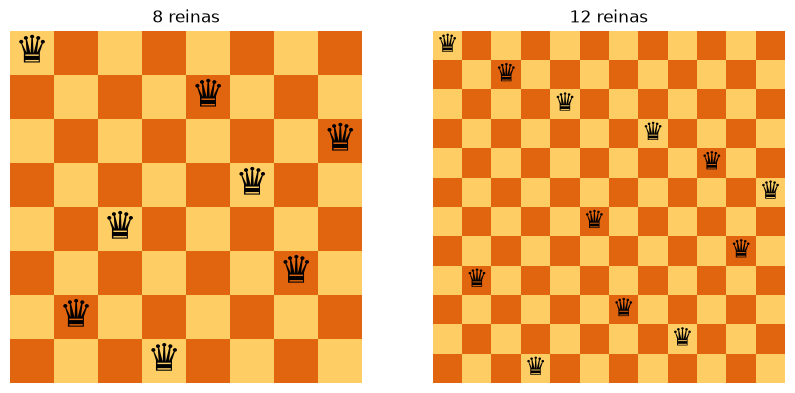

In [6]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(10, 5))
for eje, n in zip(ejes, (8, 12)):
    reinas = n_reinas(n, primera=True)[0]
    print(n, "reinas, columna de cada fila:", reinas)
    eje.imshow([[(f + c) % 2 for c in range(n)] for f in range(n)], cmap="YlOrBr", vmin=-1, vmax=2)
    for f, c in enumerate(reinas):
        eje.text(c, f, "♛", ha="center", va="center", fontsize=220 // n)
    eje.set_title(f"{n} reinas")
    eje.axis("off")
plt.show()

## 7. Sudoku

Rellenar un sudoku: buscar una casilla vacía, probar los dígitos que no aparecen en su fila, columna ni caja de 3×3 y retroceder si ninguno sirve. Comprobar que la solución es válida y respeta las pistas.

In [7]:
sudoku = [
    "53..7....",
    "6..195...",
    ".98....6.",
    "8...6...3",
    "4..8.3..1",
    "7...2...6",
    ".6....28.",
    "...419..5",
    "....8..79",
]

def posibles(t, f, c):
    usados = set(t[f]) | {t[i][c] for i in range(9)}
    cf, cc = 3 * (f // 3), 3 * (c // 3)
    usados |= {t[i][j] for i in range(cf, cf + 3) for j in range(cc, cc + 3)}
    return [d for d in range(1, 10) if d not in usados]

def resuelve_sudoku(t):
    for f in range(9):
        for c in range(9):
            if t[f][c] == 0:
                for d in posibles(t, f, c):
                    t[f][c] = d
                    if resuelve_sudoku(t):
                        return True
                t[f][c] = 0
                return False
    return True

tablero = [[0 if x == "." else int(x) for x in fila] for fila in sudoku]
assert resuelve_sudoku(tablero)
for f, fila in enumerate(tablero):
    if f in (3, 6):
        print("------+-------+------")
    print(" | ".join(" ".join(map(str, fila[i:i + 3])) for i in (0, 3, 6)))

cifras = set(range(1, 10))
assert all(set(fila) == cifras for fila in tablero)
assert all({tablero[f][c] for f in range(9)} == cifras for c in range(9))
assert all({tablero[f][c] for f in range(cf, cf + 3) for c in range(cc, cc + 3)} == cifras
           for cf in (0, 3, 6) for cc in (0, 3, 6))
assert all(x == "." or int(x) == tablero[f][c] for f, fila in enumerate(sudoku) for c, x in enumerate(fila))

5 3 4 | 6 7 8 | 9 1 2
6 7 2 | 1 9 5 | 3 4 8
1 9 8 | 3 4 2 | 5 6 7
------+-------+------
8 5 9 | 7 6 1 | 4 2 3
4 2 6 | 8 5 3 | 7 9 1
7 1 3 | 9 2 4 | 8 5 6
------+-------+------
9 6 1 | 5 3 7 | 2 8 4
2 8 7 | 4 1 9 | 6 3 5
3 4 5 | 2 8 6 | 1 7 9


## 8. Laberinto

Encontrar un camino de `S` a `E` avanzando en profundidad y retrocediendo en los callejones sin salida. El camino encontrado no tiene por qué ser el más corto: enumerar todos los caminos simples y comprobar en laberintos aleatorios que el más corto coincide con la distancia BFS (algoritmo de Lee). Dibujar los dos caminos con `matplotlib`.

In [8]:
from collections import deque

laberinto = [
    "S......#......",
    ".####.....###.",
    ".#..#.###...#.",
    ".#.##.#.###.#.",
    ".#....#...#.#.",
    ".####.###.#.#.",
    ".#........#...",
    "E#.######.###.",
    "..............",
]
MOVIMIENTOS = ((0, 1), (1, 0), (0, -1), (-1, 0))

def busca(lab, simbolo):
    return next((f, c) for f, fila in enumerate(lab) for c, v in enumerate(fila) if v == simbolo)

def libre(lab, f, c):
    return 0 <= f < len(lab) and 0 <= c < len(lab[0]) and lab[f][c] != "#"

def un_camino(lab, pos, destino, camino, visitado):
    if pos == destino:
        return list(camino)
    for df, dc in MOVIMIENTOS:
        sig = (pos[0] + df, pos[1] + dc)
        if libre(lab, *sig) and sig not in visitado:
            # no se desmarca: si desde aquí no se llegó, por otro lado tampoco
            visitado.add(sig)
            camino.append(sig)
            encontrado = un_camino(lab, sig, destino, camino, visitado)
            if encontrado:
                return encontrado
            camino.pop()
    return None

def todos_los_caminos(lab, pos, destino, camino, visitado, caminos):
    if pos == destino:
        caminos.append(list(camino))
        return
    for df, dc in MOVIMIENTOS:
        sig = (pos[0] + df, pos[1] + dc)
        if libre(lab, *sig) and sig not in visitado:
            visitado.add(sig)
            camino.append(sig)
            todos_los_caminos(lab, sig, destino, camino, visitado, caminos)
            camino.pop()
            visitado.remove(sig)

def bfs(lab, origen, destino):
    dist, cola = {origen: 0}, deque([origen])
    while cola:
        f, c = cola.popleft()
        for df, dc in MOVIMIENTOS:
            sig = (f + df, c + dc)
            if libre(lab, *sig) and sig not in dist:
                dist[sig] = dist[f, c] + 1
                cola.append(sig)
    return dist.get(destino)

def caminos_de(lab):
    origen, destino = busca(lab, "S"), busca(lab, "E")
    caminos = []
    todos_los_caminos(lab, origen, destino, [origen], {origen}, caminos)
    return un_camino(lab, origen, destino, [origen], {origen}), caminos, bfs(lab, origen, destino)

camino, caminos, distancia = caminos_de(laberinto)
mas_corto = min(caminos, key=len)
print("Primer camino:", len(camino) - 1, "pasos")
print(len(caminos), "caminos simples; el más corto tiene", len(mas_corto) - 1, "pasos")
assert len(mas_corto) - 1 == distancia

random.seed(3)
for _ in range(100):
    lab = [["#" if random.random() < 0.3 else "." for _ in range(5)] for _ in range(5)]
    lab[0][0], lab[-1][-1] = "S", "E"
    primero, todos, distancia = caminos_de(lab)
    assert (primero is None) == (distancia is None) == (not todos)
    if todos:
        assert min(map(len, todos)) - 1 == distancia

Primer camino: 35 pasos
21 caminos simples; el más corto tiene 7 pasos


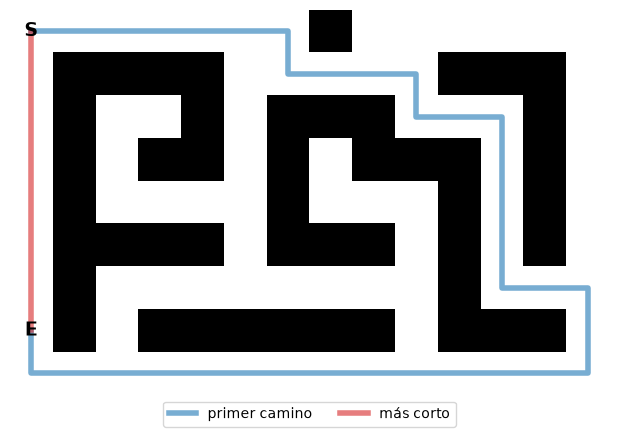

In [9]:
fig, eje = plt.subplots(figsize=(8, 5))
eje.imshow([[x == "#" for x in fila] for fila in laberinto], cmap="Greys")
for c, color, etiqueta in ((camino, "tab:blue", "primer camino"), (mas_corto, "tab:red", "más corto")):
    eje.plot([p[1] for p in c], [p[0] for p in c], color=color, linewidth=4, alpha=0.6, label=etiqueta)
for simbolo in "SE":
    f, c = busca(laberinto, simbolo)
    eje.text(c, f, simbolo, ha="center", va="center", fontsize=14, fontweight="bold")
eje.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2)
eje.axis("off")
plt.show()

## 9. Coloreado de grafos

Asignar a cada nodo uno de $m$ colores de forma que dos vecinos no tengan el mismo. Aplicarlo a un calendario de exámenes: las asignaturas que comparten alumnos no pueden examinarse el mismo día. Buscar el mínimo número de días probando $m = 1, 2, \dots$, comprobarlo con fuerza bruta en grafos aleatorios y dibujar el resultado.

In [10]:
from itertools import product
from math import cos, pi, sin

def colorea(grafo, m):
    # primero los nodos con más vecinos: fallan antes
    nodos = sorted(grafo, key=lambda n: -len(grafo[n]))
    color = {}

    def asigna(i):
        if i == len(nodos):
            return True
        n = nodos[i]
        for c in range(m):
            if all(color.get(v) != c for v in grafo[n]):
                color[n] = c
                if asigna(i + 1):
                    return True
                del color[n]
        return False

    return dict(color) if asigna(0) else None

def numero_cromatico(grafo):
    m = 1
    while (coloreado := colorea(grafo, m)) is None:
        m += 1
    return m, coloreado

def cromatico_fuerza_bruta(grafo):
    nodos = list(grafo)
    for m in range(1, len(nodos) + 1):
        for colores in product(range(m), repeat=len(nodos)):
            c = dict(zip(nodos, colores))
            if all(c[u] != c[v] for u in grafo for v in grafo[u]):
                return m

conflictos = [
    ("Cálculo", "Física"), ("Cálculo", "Programación"), ("Cálculo", "Álgebra"), ("Física", "Química"),
    ("Física", "Programación"), ("Programación", "Bases de datos"), ("Programación", "Álgebra"),
    ("Química", "Biología"), ("Biología", "Estadística"), ("Estadística", "Cálculo"),
    ("Bases de datos", "Estadística"),
]
grafo = {}
for a, b in conflictos:
    grafo.setdefault(a, set()).add(b)
    grafo.setdefault(b, set()).add(a)

dias, coloreado = numero_cromatico(grafo)
assert dias == cromatico_fuerza_bruta(grafo)
for d in range(dias):
    print(f"Día {d + 1}:", sorted(n for n, c in coloreado.items() if c == d))

random.seed(4)
for _ in range(100):
    n = random.randint(1, 6)
    g = {i: set() for i in range(n)}
    for u, v in combinations(range(n), 2):
        if random.random() < 0.5:
            g[u].add(v)
            g[v].add(u)
    m, c = numero_cromatico(g)
    assert m == cromatico_fuerza_bruta(g)
    assert all(c[u] != c[v] for u in g for v in g[u])

Día 1: ['Bases de datos', 'Cálculo', 'Química']
Día 2: ['Estadística', 'Programación']
Día 3: ['Biología', 'Física', 'Álgebra']


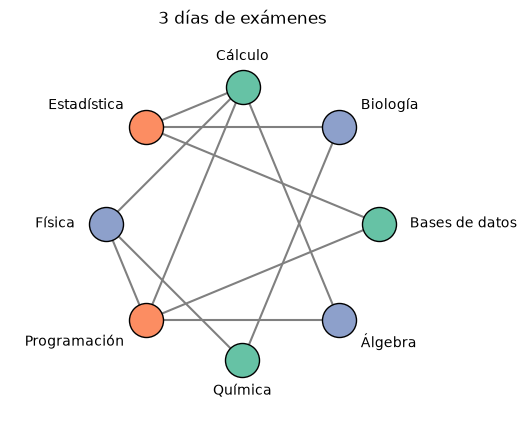

In [11]:
nodos = sorted(grafo)
posicion = {n: (cos(2 * pi * i / len(nodos)), sin(2 * pi * i / len(nodos))) for i, n in enumerate(nodos)}
fig, eje = plt.subplots(figsize=(6, 6))
for a, b in conflictos:
    eje.plot(*zip(posicion[a], posicion[b]), color="gray", zorder=1)
for n, (x, y) in posicion.items():
    eje.scatter(x, y, s=600, color=plt.cm.Set2(coloreado[n]), edgecolor="black", zorder=2)
    alineacion = "left" if x > 0.3 else "right" if x < -0.3 else "center"
    eje.annotate(n, (x, y), xytext=(22 * x, 22 * y), textcoords="offset points", ha=alineacion, va="center")
eje.set_title(f"{dias} días de exámenes")
eje.set(xlim=(-1.7, 1.7), ylim=(-1.4, 1.4))
eje.set_aspect("equal")
eje.axis("off")
plt.show()

## 10. Poda

La poda evita explorar ramas que no pueden llevar a una solución. Buscar los subconjuntos que suman un objetivo con y sin poda, contando las llamadas: con los números ordenados de mayor a menor, se corta si la suma ya se pasa o si ni sumando todos los que quedan se llega.

In [12]:
def subconjuntos_suma(numeros, objetivo, podar):
    numeros = sorted(numeros, reverse=True)
    # resto[i] es la suma de numeros[i:]
    resto = [sum(numeros[i:]) for i in range(len(numeros) + 1)]
    soluciones, actual, llamadas = [], [], 0

    def avanza(i, suma):
        nonlocal llamadas
        llamadas += 1
        if podar and (suma > objetivo or suma + resto[i] < objetivo):
            return
        if i == len(numeros):
            if suma == objetivo:
                soluciones.append(tuple(actual))
            return
        actual.append(numeros[i])
        avanza(i + 1, suma + numeros[i])
        actual.pop()
        avanza(i + 1, suma)

    avanza(0, 0)
    return soluciones, llamadas

random.seed(5)
print(f"{'n':>3} {'sin poda':>10} {'con poda':>10} {'soluciones':>11}")
for n in (8, 12, 16, 18):
    numeros = [random.randint(1, 100) for _ in range(n)]
    objetivo = sum(numeros) // 4
    sin_poda, llamadas_sin = subconjuntos_suma(numeros, objetivo, False)
    con_poda, llamadas_con = subconjuntos_suma(numeros, objetivo, True)
    assert sin_poda == con_poda
    print(f"{n:>3} {llamadas_sin:>10} {llamadas_con:>10} {len(con_poda):>11}")

  n   sin poda   con poda  soluciones
  8        511         67           1
 12       8191        249          10
 16     131071       2319          62


 18     524287       5043         183
